# **MAJOR PROJECT — DIABETES HEALTH INDICATORS ANALYSIS AND PREDICTION**

Objective: To analyze health indicators associated with diabetes and develop machine learning models to predict diabetes status.

Tools Used: Python, Pandas, NumPy, Matplotlib, Seaborn, and Scikit-learn.


IMPORTED LIBRARIES

In [65]:
# IMPORTED LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully")


All libraries imported successfully


LOADING DATASET

In [66]:
# LOADING DATASET

df_012 = pd.read_csv('diabetes_012_health_indicators_BRFSS2015.csv')

df_binary_5050 = pd.read_csv('diabetes_binary_5050split_health_indicators_BRFSS2015.csv')

df_binary = pd.read_csv('diabetes_binary_health_indicators_BRFSS2015.csv')

print("Loaded dataset successfully")

Loaded dataset successfully


 COMPARING THE THREE DATASETS

In [67]:
# COMPARING THE THREE DATASETS

print("Dataset 1 - Diabetes 012")
print(df_012.shape)

print("\nDataset 2 - Diabetes Binary 5050")
print(df_binary_5050.shape)

print("\nDataset 3 - Diabetes Binary")
print(df_binary.shape)

Dataset 1 - Diabetes 012
(253680, 22)

Dataset 2 - Diabetes Binary 5050
(70692, 22)

Dataset 3 - Diabetes Binary
(253680, 22)


 TOTAL DATASET STRUCTURE AND SUMMARY

In [68]:
# TOTAL DATASET STRUCTURE AND SUMMARY

print("Dataset 1 - Diabetes 012")
df_012.info()

print("\nDataset 2 - Diabetes Binary 5050")
df_binary_5050.info()

print("\nDataset 3 - Diabetes Binary")
df_binary.info()

Dataset 1 - Diabetes 012
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_012          253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               25368

DETECTING MISSING VALUES AND DUPLICATES

In [69]:
# DETECTING MISSING VALUES AND DUPLICATES

print("Dataset 1 - Diabetes 012")
print("Missing Values:")
print(df_012.isnull().sum())
print("Duplicate Rows:", df_012.duplicated().sum())

print("\nDataset 2 - Diabetes Binary 5050")
print("Missing Values:")
print(df_binary_5050.isnull().sum())
print("Duplicate Rows:", df_binary_5050.duplicated().sum())

print("\nDataset 3 - Diabetes Binary")
print("Missing Values:")
print(df_binary.isnull().sum())
print("Duplicate Rows:", df_binary.duplicated().sum())

Dataset 1 - Diabetes 012
Missing Values:
Diabetes_012            0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64
Duplicate Rows: 23899

Dataset 2 - Diabetes Binary 5050
Missing Values:
Diabetes_binary         0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsum

CHECKING TARGET VARIABLE AND CLASS BALANCE

In [70]:
# CHECKING TARGET VARIABLE AND CLASS BALANCE

print("Dataset 1 - Diabetes 012")
print(df_012['Diabetes_012'].value_counts())
print("\nDataset 1 - Class Percentage")
print(df_012['Diabetes_012'].value_counts(normalize=True) * 100)

print("\nDataset 2 - Diabetes Binary 5050")
print(df_binary_5050['Diabetes_binary'].value_counts())
print("\nDataset 2 - Class Percentage")
print(df_binary_5050['Diabetes_binary'].value_counts(normalize=True) * 100)

print("\nDataset 3 - Diabetes Binary")
print(df_binary['Diabetes_binary'].value_counts())
print("\nDataset 3 - Class Percentage")
print(df_binary['Diabetes_binary'].value_counts(normalize=True) * 100)

Dataset 1 - Diabetes 012
Diabetes_012
0.0    213703
2.0     35346
1.0      4631
Name: count, dtype: int64

Dataset 1 - Class Percentage
Diabetes_012
0.0    84.241170
2.0    13.933302
1.0     1.825528
Name: proportion, dtype: float64

Dataset 2 - Diabetes Binary 5050
Diabetes_binary
0.0    35346
1.0    35346
Name: count, dtype: int64

Dataset 2 - Class Percentage
Diabetes_binary
0.0    50.0
1.0    50.0
Name: proportion, dtype: float64

Dataset 3 - Diabetes Binary
Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64

Dataset 3 - Class Percentage
Diabetes_binary
0.0    86.066698
1.0    13.933302
Name: proportion, dtype: float64


 DATA VISUALIZATION - DIABETES CLASS DISTRIBUTION

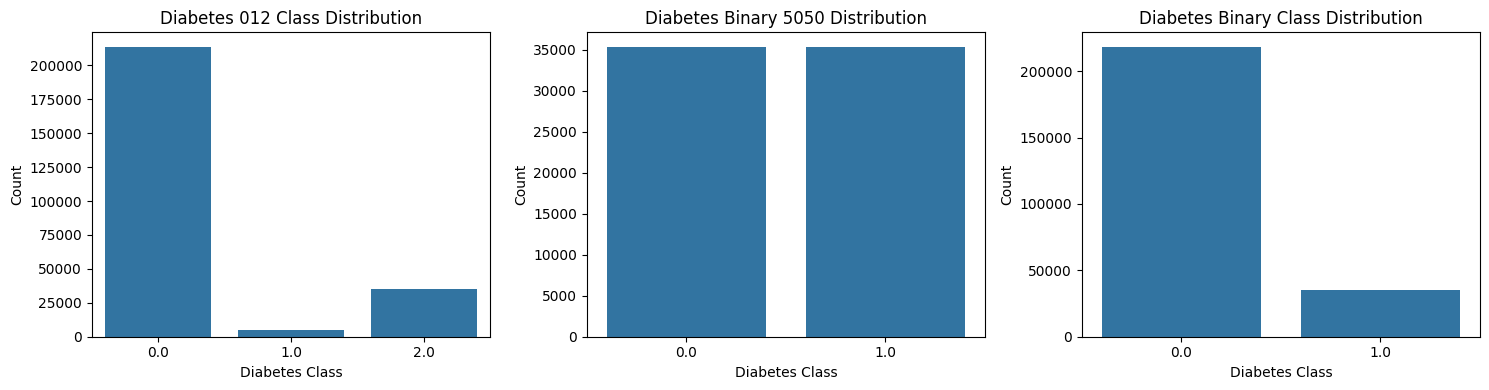

Class distribution visualization completed successfully


In [71]:
# DATA VISUALIZATION - DIABETES CLASS DISTRIBUTION

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.countplot(x='Diabetes_012', data=df_012)
plt.title('Diabetes 012 Class Distribution')
plt.xlabel('Diabetes Class')
plt.ylabel('Count')

plt.subplot(1, 3, 2)
sns.countplot(x='Diabetes_binary', data=df_binary_5050)
plt.title('Diabetes Binary 5050 Distribution')
plt.xlabel('Diabetes Class')
plt.ylabel('Count')

plt.subplot(1, 3, 3)
sns.countplot(x='Diabetes_binary', data=df_binary)
plt.title('Diabetes Binary Class Distribution')
plt.xlabel('Diabetes Class')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

print("Class distribution visualization completed successfully")


ANALYZING HEALTH INDICATORS

HEALTH INDICATORS SUMMARY
       Diabetes_binary         HighBP       HighChol      CholCheck  \
count    253680.000000  253680.000000  253680.000000  253680.000000   
mean          0.139333       0.429001       0.424121       0.962670   
std           0.346294       0.494934       0.494210       0.189571   
min           0.000000       0.000000       0.000000       0.000000   
25%           0.000000       0.000000       0.000000       1.000000   
50%           0.000000       0.000000       0.000000       1.000000   
75%           0.000000       1.000000       1.000000       1.000000   
max           1.000000       1.000000       1.000000       1.000000   

                 BMI         Smoker         Stroke  HeartDiseaseorAttack  \
count  253680.000000  253680.000000  253680.000000         253680.000000   
mean       28.382364       0.443169       0.040571              0.094186   
std         6.608694       0.496761       0.197294              0.292087   
min        12.000000       0.0

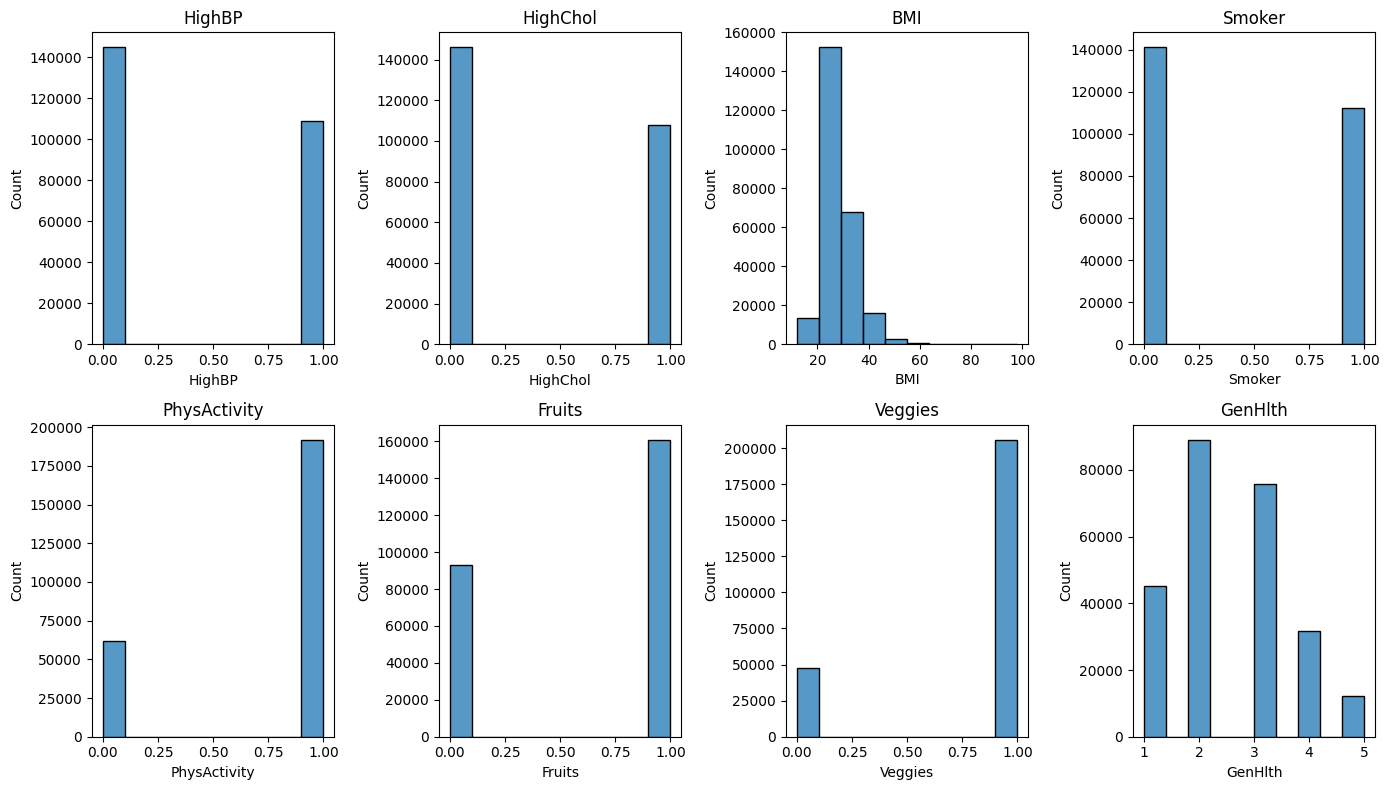

Health indicators analysis completed successfully


In [72]:
# ANALYZING HEALTH INDICATORS

print("HEALTH INDICATORS SUMMARY")
print(df_binary.describe())

print("\nDIABETES CLASS COUNTS")
print(df_binary['Diabetes_binary'].value_counts())

# VISUALIZING IMPORTANT HEALTH INDICATORS

health_columns = [
    'HighBP',
    'HighChol',
    'BMI',
    'Smoker',
    'PhysActivity',
    'Fruits',
    'Veggies',
    'GenHlth'
]

plt.figure(figsize=(14, 8))

for i, column in enumerate(health_columns):
    plt.subplot(2, 4, i + 1)
    sns.histplot(data=df_binary, x=column, bins=10)
    plt.title(column)

plt.tight_layout()
plt.show()

print("Health indicators analysis completed successfully")


CORRELATION ANALYSIS

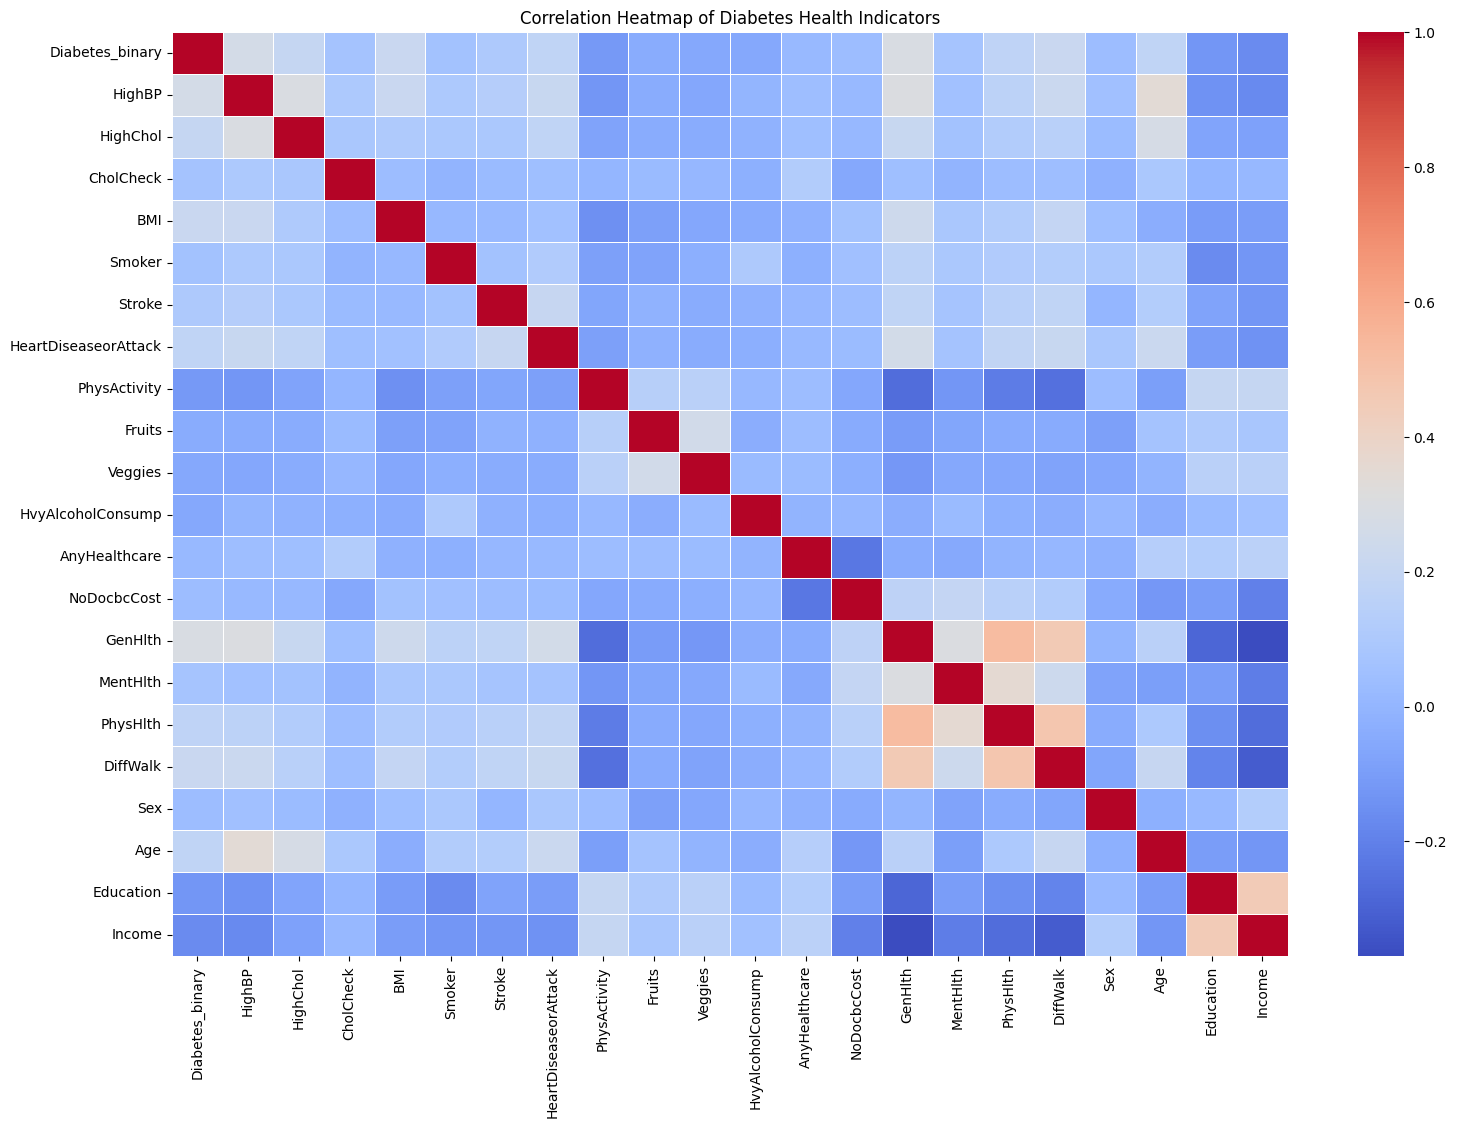

Correlation analysis completed successfully


In [73]:
# CORRELATION ANALYSIS

correlation = df_binary.corr()

plt.figure(figsize=(18, 12))

sns.heatmap(
    correlation,
    cmap='coolwarm',
    annot=False,
    linewidths=0.5
)

plt.title('Correlation Heatmap of Diabetes Health Indicators')
plt.show()

print("Correlation analysis completed successfully")


PREPARING DATA FOR MACHINE LEARNING

In [74]:
# PREPARING DATA FOR MACHINE LEARNING

X = df_binary.drop('Diabetes_binary', axis=1)

y = df_binary['Diabetes_binary']

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nInput Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

print("\nData preparation completed successfully")


Input Features Shape: (253680, 21)
Target Variable Shape: (253680,)

Input Features:
   HighBP  HighChol  CholCheck   BMI  Smoker  Stroke  HeartDiseaseorAttack  \
0     1.0       1.0        1.0  40.0     1.0     0.0                   0.0   
1     0.0       0.0        0.0  25.0     1.0     0.0                   0.0   
2     1.0       1.0        1.0  28.0     0.0     0.0                   0.0   
3     1.0       0.0        1.0  27.0     0.0     0.0                   0.0   
4     1.0       1.0        1.0  24.0     0.0     0.0                   0.0   

   PhysActivity  Fruits  Veggies  ...  AnyHealthcare  NoDocbcCost  GenHlth  \
0           0.0     0.0      1.0  ...            1.0          0.0      5.0   
1           1.0     0.0      0.0  ...            0.0          1.0      3.0   
2           0.0     1.0      0.0  ...            1.0          1.0      5.0   
3           1.0     1.0      1.0  ...            1.0          0.0      2.0   
4           1.0     1.0      1.0  ...            1.0    

SPLITTING DATA INTO TRAINING AND TESTING SETS

In [75]:
# SPLITTING DATA INTO TRAINING AND TESTING SETS

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

print("\nData splitting completed successfully")


Training Data Shape: (202944, 21)
Testing Data Shape: (50736, 21)

Training Target Shape: (202944,)
Testing Target Shape: (50736,)

Data splitting completed successfully


FEATURE SCALING

In [76]:
# FEATURE SCALING

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Training Data After Scaling:", X_train_scaled.shape)
print("Testing Data After Scaling:", X_test_scaled.shape)

print("\nFeature scaling completed successfully")

Training Data After Scaling: (202944, 21)
Testing Data After Scaling: (50736, 21)

Feature scaling completed successfully


TRAINING THE LOGISTIC REGRESSION MODEL

In [77]:
# TRAINING THE LOGISTIC REGRESSION MODEL

logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully")

Logistic Regression Model Trained Successfully


PREDICTING DIABETES USING LOGISTIC REGRESSION

In [78]:
# PREDICTING DIABETES USING LOGISTIC REGRESSION

y_pred_logistic = logistic_model.predict(X_test_scaled)

print("First 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Values:")
print(y_pred_logistic[:10])

print("\nPredictions completed successfully")


First 10 Actual Values:
[0. 1. 0. 0. 1. 0. 0. 0. 0. 0.]

First 10 Predicted Values:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

Predictions completed successfully


EVALUATING THE LOGISTIC REGRESSION MODEL

In [79]:

# EVALUATING THE LOGISTIC REGRESSION MODEL

logistic_accuracy = accuracy_score(y_test, y_pred_logistic)

logistic_precision = precision_score(y_test, y_pred_logistic, zero_division=0)

logistic_recall = recall_score(y_test, y_pred_logistic, zero_division=0)

logistic_f1 = f1_score(y_test, y_pred_logistic, zero_division=0)

print("LOGISTIC REGRESSION MODEL PERFORMANCE")

print("Accuracy:", round(logistic_accuracy * 100, 2), "%")
print("Precision:", round(logistic_precision * 100, 2), "%")
print("Recall:", round(logistic_recall * 100, 2), "%")
print("F1-Score:", round(logistic_f1 * 100, 2), "%")

print("\nModel evaluation completed successfully")

LOGISTIC REGRESSION MODEL PERFORMANCE
Accuracy: 86.21 %
Precision: 51.71 %
Recall: 15.83 %
F1-Score: 24.24 %

Model evaluation completed successfully


CONFUSION MATRIX VISUALIZATION

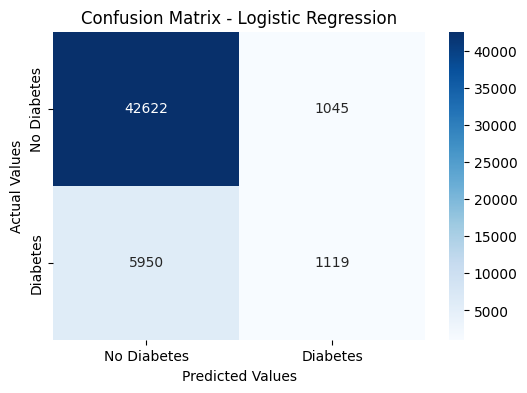

Confusion matrix generated successfully


In [80]:
# CONFUSION MATRIX VISUALIZATION

cm = confusion_matrix(y_test, y_pred_logistic)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Diabetes', 'Diabetes'],
    yticklabels=['No Diabetes', 'Diabetes']
)

plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.show()

print("Confusion matrix generated successfully")


TRAINING THE RANDOM FOREST MODEL

In [81]:
# TRAINING THE RANDOM FOREST MODEL

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=14,
    min_samples_leaf=20,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully")

Random Forest Model Trained Successfully


 PREDICTING DIABETES USING RANDOM FOREST

In [82]:
# PREDICTING DIABETES USING RANDOM FOREST

y_pred_rf = random_forest_model.predict(X_test)

print("First 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Values:")
print(y_pred_rf[:10])

print("\nRandom Forest predictions completed successfully")

First 10 Actual Values:
[0. 1. 0. 0. 1. 0. 0. 0. 0. 0.]

First 10 Predicted Values:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

Random Forest predictions completed successfully


EVALUATING THE RANDOM FOREST MODEL

In [83]:
# EVALUATING THE RANDOM FOREST MODEL

rf_accuracy = accuracy_score(y_test, y_pred_rf)

rf_precision = precision_score(y_test, y_pred_rf, zero_division=0)

rf_recall = recall_score(y_test, y_pred_rf, zero_division=0)

rf_f1 = f1_score(y_test, y_pred_rf, zero_division=0)

print("RANDOM FOREST MODEL PERFORMANCE")

print("Accuracy:", round(rf_accuracy * 100, 2), "%")
print("Precision:", round(rf_precision * 100, 2), "%")
print("Recall:", round(rf_recall * 100, 2), "%")
print("F1-Score:", round(rf_f1 * 100, 2), "%")

print("\nRandom Forest evaluation completed successfully")


RANDOM FOREST MODEL PERFORMANCE
Accuracy: 86.53 %
Precision: 58.94 %
Recall: 10.96 %
F1-Score: 18.49 %

Random Forest evaluation completed successfully


 COMPARING BOTH MACHINE LEARNING MODELS

In [84]:
# COMPARING BOTH MACHINE LEARNING MODELS

model_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [logistic_accuracy, rf_accuracy],
    'Precision': [logistic_precision, rf_precision],
    'Recall': [logistic_recall, rf_recall],
    'F1-Score': [logistic_f1, rf_f1]
})

print("MODEL PERFORMANCE COMPARISON")
print(model_comparison.round(4))

print("\nModel comparison completed successfully")

MODEL PERFORMANCE COMPARISON
                 Model  Accuracy  Precision  Recall  F1-Score
0  Logistic Regression    0.8621     0.5171  0.1583    0.2424
1        Random Forest    0.8653     0.5894  0.1096    0.1849

Model comparison completed successfully


VISUALIZING MODEL PERFORMANCE COMPARISON

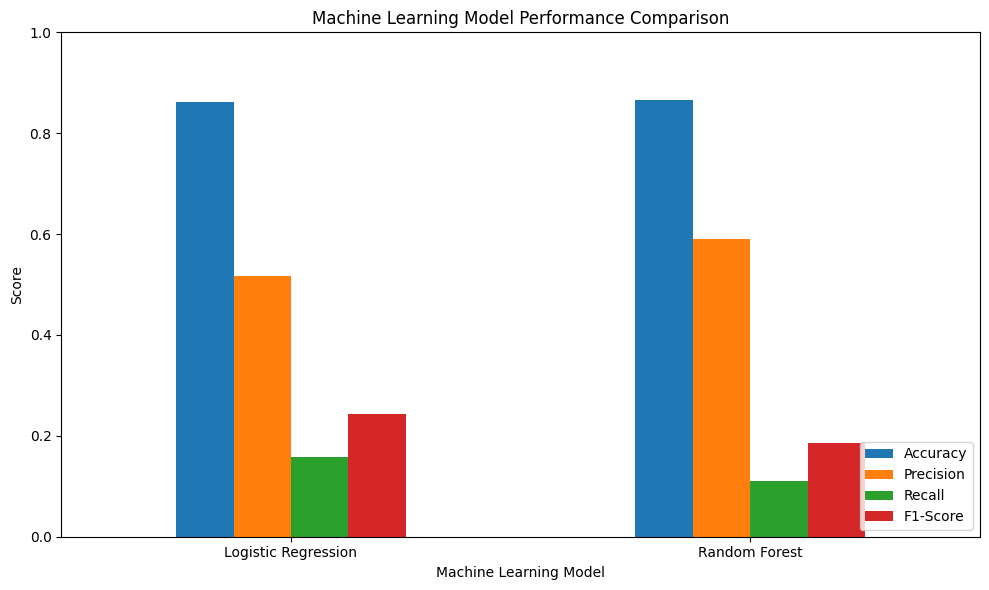

Model comparison visualization completed successfully


In [85]:
# VISUALIZING MODEL PERFORMANCE COMPARISON

model_comparison_plot = model_comparison.set_index('Model')

model_comparison_plot.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Machine Learning Model Performance Comparison')
plt.xlabel('Machine Learning Model')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

print("Model comparison visualization completed successfully")


FEATURE IMPORTANCE ANALYSIS USING RANDOM FOREST

TOP 10 IMPORTANT HEALTH INDICATORS
                 Feature  Importance
13               GenHlth    0.186451
0                 HighBP    0.177160
3                    BMI    0.173552
1               HighChol    0.084631
18                   Age    0.080850
16              DiffWalk    0.066920
15              PhysHlth    0.044415
20                Income    0.039561
6   HeartDiseaseorAttack    0.037812
19             Education    0.018978


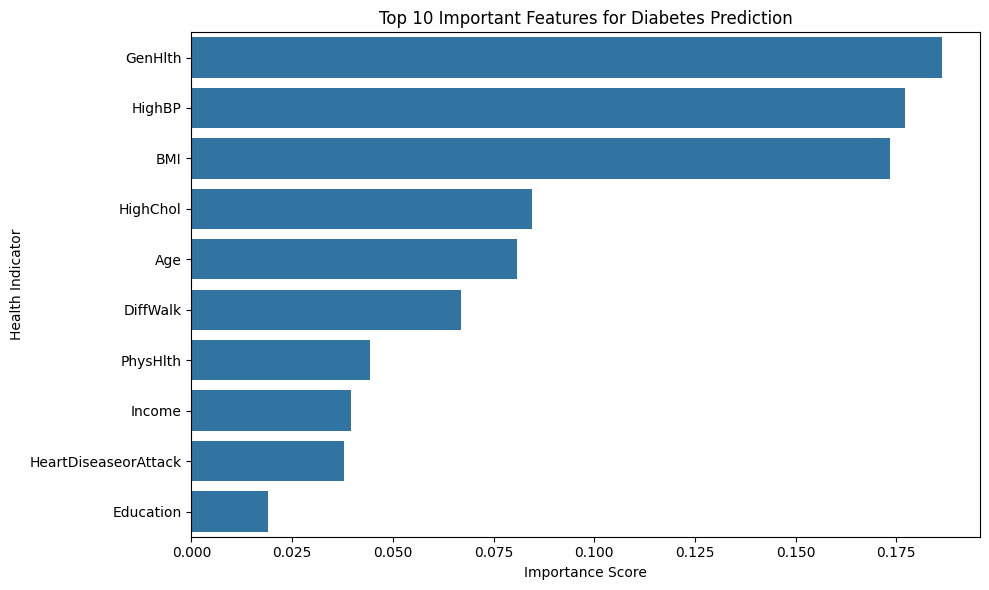

Feature importance analysis completed successfully


In [86]:
# FEATURE IMPORTANCE ANALYSIS USING RANDOM FOREST

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("TOP 10 IMPORTANT HEALTH INDICATORS")
print(feature_importance.head(10))

# VISUALIZING FEATURE IMPORTANCE

plt.figure(figsize=(10, 6))

sns.barplot(
    x='Importance',
    y='Feature',
    data=feature_importance.head(10)
)

plt.title('Top 10 Important Features for Diabetes Prediction')
plt.xlabel('Importance Score')
plt.ylabel('Health Indicator')

plt.tight_layout()
plt.show()

print("Feature importance analysis completed successfully")

ROC CURVE AND AUC ANALYSIS


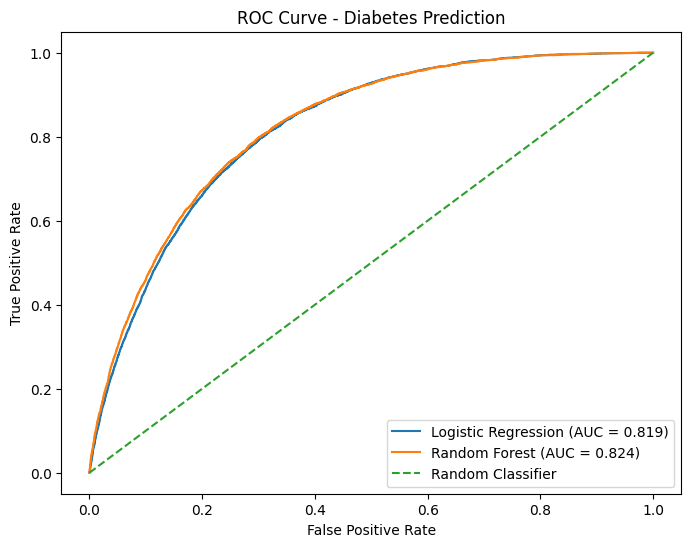

Logistic Regression AUC: 0.8192
Random Forest AUC: 0.824

ROC and AUC analysis completed successfully


In [87]:
# ROC CURVE AND AUC ANALYSIS

y_prob_logistic = logistic_model.predict_proba(X_test_scaled)[:, 1]

y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

fpr_logistic, tpr_logistic, thresholds_logistic = roc_curve(
    y_test, y_prob_logistic
)

fpr_rf, tpr_rf, thresholds_rf = roc_curve(
    y_test, y_prob_rf
)

auc_logistic = roc_auc_score(y_test, y_prob_logistic)

auc_rf = roc_auc_score(y_test, y_prob_rf)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_logistic,
    tpr_logistic,
    label='Logistic Regression (AUC = ' + str(round(auc_logistic, 3)) + ')'
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label='Random Forest (AUC = ' + str(round(auc_rf, 3)) + ')'
)

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.title('ROC Curve - Diabetes Prediction')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

print("Logistic Regression AUC:", round(auc_logistic, 4))
print("Random Forest AUC:", round(auc_rf, 4))

print("\nROC and AUC analysis completed successfully")

CLASSIFICATION REPORT

In [88]:
# CLASSIFICATION REPORT

print("LOGISTIC REGRESSION CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred_logistic,
    target_names=['No Diabetes', 'Diabetes'],
    zero_division=0
))

print("\nRANDOM FOREST CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=['No Diabetes', 'Diabetes'],
    zero_division=0
))

print("\nClassification reports generated successfully")

LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

 No Diabetes       0.88      0.98      0.92     43667
    Diabetes       0.52      0.16      0.24      7069

    accuracy                           0.86     50736
   macro avg       0.70      0.57      0.58     50736
weighted avg       0.83      0.86      0.83     50736


RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

 No Diabetes       0.87      0.99      0.93     43667
    Diabetes       0.59      0.11      0.18      7069

    accuracy                           0.87     50736
   macro avg       0.73      0.55      0.56     50736
weighted avg       0.83      0.87      0.82     50736


Classification reports generated successfully


In [89]:

# FINAL MODEL PERFORMANCE SUMMARY

final_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [logistic_accuracy, rf_accuracy],
    'Precision': [logistic_precision, rf_precision],
    'Recall': [logistic_recall, rf_recall],
    'F1-Score': [logistic_f1, rf_f1],
    'AUC': [auc_logistic, auc_rf]
})

print("FINAL MODEL PERFORMANCE SUMMARY")
print(final_comparison.round(4))

# IDENTIFYING THE MODEL WITH HIGHER AUC

if auc_logistic > auc_rf:
    print("\nLogistic Regression has the higher AUC score.")
elif auc_rf > auc_logistic:
    print("\nRandom Forest has the higher AUC score.")
else:
    print("\nBoth models have the same AUC score.")

print("\nFinal model comparison completed successfully")


FINAL MODEL PERFORMANCE SUMMARY
                 Model  Accuracy  Precision  Recall  F1-Score     AUC
0  Logistic Regression    0.8621     0.5171  0.1583    0.2424  0.8192
1        Random Forest    0.8653     0.5894  0.1096    0.1849  0.8240

Random Forest has the higher AUC score.

Final model comparison completed successfully


SAVING THE MODEL RESULTS

In [90]:
# SAVING THE MODEL RESULTS

final_comparison.to_csv(
    'diabetes_model_comparison.csv',
    index=False
)

print("Model comparison saved successfully")
print("File Name: diabetes_model_comparison.csv")


Model comparison saved successfully
File Name: diabetes_model_comparison.csv


SAVING THE TRAINED MACHINE LEARNING MODELS

In [91]:
# SAVING THE TRAINED MACHINE LEARNING MODELS

import joblib

joblib.dump(logistic_model, 'logistic_regression_model.pkl')

joblib.dump(random_forest_model, 'random_forest_model.pkl', compress=3)

joblib.dump(scaler, 'diabetes_feature_scaler.pkl')

print("Models saved successfully")
print("1. logistic_regression_model.pkl")
print("2. random_forest_model.pkl")
print("3. diabetes_feature_scaler.pkl")

Models saved successfully
1. logistic_regression_model.pkl
2. random_forest_model.pkl
3. diabetes_feature_scaler.pkl


FINAL REPORT


```
MAJOR PROJECT REPORT
DIABETES HEALTH INDICATORS ANALYSIS AND PREDICTION

============================================================
1. EXECUTIVE SUMMARY
============================================================

This project analyzes health indicators associated with diabetes
and builds machine learning models to predict diabetes status.
The project uses the BRFSS 2015 Health Indicators dataset and
compares Logistic Regression and Random Forest classifiers.

Exploratory data analysis, data quality checks, class
distribution analysis, correlation analysis, feature scaling,
model training, evaluation, feature importance analysis, and
ROC-AUC comparison were performed.

The final comparison shows that Random Forest achieved the
higher ROC-AUC score and precision, while Logistic Regression
achieved higher recall and F1-score for the diabetes class.
Both models had limited recall for identifying people in the
diabetes class, so accuracy alone should not be treated as
evidence of strong diabetes detection.

============================================================
2. DATASET OVERVIEW
============================================================

Three datasets were examined.

Dataset 1: Diabetes 012

Number of Rows: 253,680
Number of Columns: 22
Target Variable: Diabetes_012

Target Classes:
- No Diabetes: 213,703 (84.24%)
- Prediabetes: 4,631 (1.83%)
- Diabetes: 35,346 (13.93%)

Dataset 2: Diabetes Binary 5050

Number of Rows: 70,692
Number of Columns: 22
Target Variable: Diabetes_binary

Target Classes:
- No Diabetes: 35,346 (50.00%)
- Diabetes: 35,346 (50.00%)

Dataset 3: Diabetes Binary

Number of Rows: 253,680
Number of Columns: 22
Target Variable: Diabetes_binary

Target Classes:
- No Diabetes: 218,334 (86.07%)
- Diabetes: 35,346 (13.93%)

The main machine learning analysis used Dataset 3, containing
253,680 records, 21 input features, and one target variable.

============================================================
3. DATA CLEANING AND QUALITY CHECKS
============================================================

Missing Values:
- No missing values were reported in any of the three datasets.

Duplicate Rows Reported:
- Diabetes 012 dataset: 23,899
- Diabetes Binary 5050 dataset: 1,635
- Diabetes Binary dataset: 24,206

Note:
The notebook checked for duplicate rows but did not remove them
before model training. Duplicate records may affect model
evaluation and should be considered in future improvements.

============================================================
4. EXPLORATORY DATA ANALYSIS (EDA)
============================================================

The following analyses were completed:

- Compared the structure and dimensions of all three datasets.
- Checked missing values and duplicate rows.
- Examined target class counts and class percentages.
- Visualized diabetes class distributions.
- Summarized health indicator variables using descriptive statistics.
- Created a correlation heatmap to examine relationships between variables.

Key Observations:

- The Diabetes 012 dataset is dominated by the no-diabetes class
(84.24%).
- The full binary dataset is imbalanced, with 86.07% no diabetes
and 13.93% diabetes.
- The Diabetes Binary 5050 dataset has equal numbers of records
in both classes.
- The average BMI in the full binary dataset was approximately 28.38.
- Approximately 42.90% of records had HighBP = 1.
- Approximately 42.41% of records had HighChol = 1.
- Approximately 75.65% of records had PhysActivity = 1.

============================================================
5. DATA PREPARATION
============================================================

Target Variable: Diabetes_binary
Number of Input Features: 21

The target column Diabetes_binary was separated from the input
features.

Training Set:
- Records: 202,944
- Features: 21

Testing Set:
- Records: 50,736
- Features: 21

The data was split using an 80/20 train-test split with
stratification and random_state = 42.

StandardScaler was used to scale the training and testing
features for Logistic Regression. The Random Forest model was
trained using the original input features.

============================================================
6. MACHINE LEARNING MODELS
============================================================

Two classification algorithms were developed.

1. LOGISTIC REGRESSION

- Used StandardScaler-scaled features.
- Maximum iterations: 1000.
- Evaluated using accuracy, precision, recall, F1-score, and
ROC-AUC.

2. RANDOM FOREST CLASSIFIER

- Trained on the original input features.
- Settings: n_estimators = 100, max_depth = 14,
min_samples_leaf = 20, random_state = 42.
- The depth and leaf limits keep the saved model small enough
for web deployment (about 9 MB compressed, compared with about
566 MB for a fully grown forest).
- Used to evaluate classification performance and feature
importance.
- Evaluated using accuracy, precision, recall, F1-score, and
ROC-AUC.

Both models were compared to identify their strengths and
limitations.

============================================================
7. MODEL PERFORMANCE COMPARISON
============================================================

Model Performance Results:

Metric                 Logistic Regression     Random Forest
------------------------------------------------------------
Accuracy               86.21%                  86.53%
Precision              51.71%                  58.94%
Recall                 15.83%                  10.96%
F1-Score               24.24%                  18.49%
ROC-AUC                0.8192                  0.8240

Interpretation:

- Random Forest achieved slightly higher accuracy and precision.
- Random Forest achieved the higher ROC-AUC score.
- Logistic Regression achieved higher recall and F1-score for the
diabetes class.
- Both models detected only a relatively small proportion of
actual diabetes cases.
- The high accuracy is influenced by the larger no-diabetes class
and should not be considered on its own.

============================================================
8. CLASSIFICATION REPORT SUMMARY
============================================================

LOGISTIC REGRESSION

No Diabetes:
- Precision: 0.88
- Recall: 0.98
- F1-score: 0.92
- Support: 43,667

Diabetes:
- Precision: 0.52
- Recall: 0.16
- F1-score: 0.24
- Support: 7,069

Overall Accuracy: 0.86


RANDOM FOREST

No Diabetes:
- Precision: 0.87
- Recall: 0.99
- F1-score: 0.93
- Support: 43,667

Diabetes:
- Precision: 0.59
- Recall: 0.11
- F1-score: 0.18
- Support: 7,069

Overall Accuracy: 0.87

============================================================
9. FEATURE IMPORTANCE ANALYSIS
============================================================

The top 10 features reported by the Random Forest model were:

Rank   Feature                  Importance
-------------------------------------------
1      GenHlth                  0.186451
2      HighBP                   0.177160
3      BMI                      0.173552
4      HighChol                 0.084631
5      Age                      0.080850
6      DiffWalk                 0.066920
7      PhysHlth                 0.044415
8      Income                   0.039561
9      HeartDiseaseorAttack     0.037812
10     Education                0.018978

General health (GenHlth) had the highest feature importance in
the fitted Random Forest model, followed by HighBP and BMI.

These values indicate the importance of each feature to the
fitted model. They do not prove that a feature causes diabetes.

============================================================
10. ROC CURVE AND AUC ANALYSIS
============================================================

Logistic Regression AUC: 0.8192
Random Forest AUC: 0.8240

Random Forest achieved the higher AUC score, indicating slightly
better overall ranking performance between the two models on
this test set.

However, both models had low recall for the diabetes class.
Therefore, further improvements are needed to identify more
diabetes cases correctly.

============================================================
11. KEY FINDINGS
============================================================

- The full binary dataset contains 253,680 records and 21 input
health indicators.
- No missing values were reported.
- The full binary target variable is imbalanced, with 13.93%
diabetes cases.
- GenHlth, HighBP, and BMI were the most important features in
the Random Forest model.
- Age, HighChol, DiffWalk, and PhysHlth were also among the
top-ranked features.
- Random Forest achieved an AUC of 0.8240, accuracy of 86.53%,
and precision of 58.94%.
- Logistic Regression achieved recall of 15.83% and F1-score of
24.24% for the diabetes class.
- Improving detection of the diabetes class should be a priority
in future model development.

============================================================
12. PROJECT OUTPUTS
============================================================

The notebook includes the following outputs:

- Dataset loading and comparison
- Dataset structure and summary
- Missing-value and duplicate checks
- Target class distribution analysis
- Health indicator descriptive statistics
- Correlation heatmap
- Train-test split and feature scaling
- Logistic Regression model and evaluation
- Random Forest model and evaluation
- Model performance comparison
- Random Forest feature importance chart
- ROC curves and AUC comparison
- Classification reports
- Final model performance summary
- Streamlit dashboard for analysis and prediction

============================================================
13. LIMITATIONS AND FUTURE SCOPE
============================================================

LIMITATIONS

- The target classes in the full binary dataset are imbalanced.
- Duplicate rows were identified but were not removed before
model training.
- Both models have low recall for the diabetes class.
- The Random Forest depth was limited so the saved model could be
deployed online, which may trade some recall for size.
- Feature importance and model predictions do not establish
medical causation or provide a diagnosis.

FUTURE IMPROVEMENTS

- Evaluate class-weighting and resampling techniques on the
training set.
- Tune classification thresholds to improve diabetes-class recall.
- Perform hyperparameter tuning and cross-validation.
- Reassess results after handling duplicate records appropriately.
- Evaluate precision-recall curves and additional metrics suited
to imbalanced data.
- Validate the model on independent data before considering
real-world use.

============================================================
14. CONCLUSION
============================================================

The project successfully analyzed diabetes-related health
indicators and developed two machine learning classification
models.

Random Forest produced the higher ROC-AUC score of 0.8240 and
precision of 58.94%, while Logistic Regression achieved the
higher diabetes-class recall of 15.83% and F1-score of 24.24%.

Although the models achieved accuracy close to 86%, their low
recall for the diabetes class shows that many diabetes cases were
not identified. Therefore, further work is needed to improve
class detection and validate the models.

This project demonstrates how exploratory data analysis and
machine learning can be applied to health indicator data. It is
intended for educational purposes and must not be used as a
medical diagnostic tool.

====================== END OF REPORT ======================
```

Create the Streamlit App for Diabetes Prediction

In [92]:
%%writefile app.py

import io
import os
import joblib
import numpy as np
import pandas as pd
import streamlit as st
import plotly.express as px

# =========================================================
# THEME COLOURS (replaces Streamlit's default red/orange)
# =========================================================
try:
    st._config.set_option("theme.base", "dark")
    st._config.set_option("theme.primaryColor", "#f438d0")
    st._config.set_option("theme.backgroundColor", "#170b29")
    st._config.set_option("theme.secondaryBackgroundColor", "#211035")
    st._config.set_option("theme.textColor", "#f4e9ff")
except Exception:
    pass

# =========================================================
# PAGE CONFIGURATION
# =========================================================
st.set_page_config(
    page_title="Diabetes Health Analytics",
    page_icon="📊",
    layout="wide",
    initial_sidebar_state="expanded"
)

# =========================================================
# DARK PURPLE + MAGENTA + VIOLET THEME
# =========================================================
st.markdown("""
<style>
/* ==========================================
   BASE
   ========================================== */
.stApp {
    background: linear-gradient(135deg, #170b29, #24103c 65%, #1a0c30);
    color: #f4e9ff;
    font-family: "Inter", "Segoe UI", sans-serif;
}

[data-testid="stHeader"] { background: #170b29; }
[data-testid="stAppViewContainer"] { background: transparent; }

h1, h2, h3, h4 {
    color: #fff3ff !important;
    font-weight: 700 !important;
    letter-spacing: -0.3px;
}

p, li, label { color: #ddcdee; }

[data-testid="stCaptionContainer"] p { color: #c0acd8 !important; }

hr { border-color: #442653 !important; }

::-webkit-scrollbar { width: 8px; height: 8px; }
::-webkit-scrollbar-track { background: #10091c; }
::-webkit-scrollbar-thumb {
    background: #442653;
    border-radius: 8px;
}
::-webkit-scrollbar-thumb:hover { background: #ff58d7; }

/* ==========================================
   SIDEBAR
   ========================================== */
[data-testid="stSidebar"],
[data-testid="stSidebar"] > div:first-child {
    background: #10091c !important;
}

[data-testid="stSidebar"] { border-right: 1px solid #38204a; }

[data-testid="stSidebar"] h1,
[data-testid="stSidebar"] label,
[data-testid="stSidebar"] p { color: #f0e2ff !important; }

[data-testid="stSidebar"] h2,
[data-testid="stSidebar"] h3 { color: #ff8ce8 !important; }

[data-testid="stSidebar"] [data-testid="stWidgetLabel"] p {
    color: #decaf0 !important;
    font-weight: 600 !important;
}

[data-testid="stSidebar"] .stButton button,
[data-testid="stSidebar"] .stDownloadButton button {
    background: linear-gradient(100deg, #7125b7, #a626c9) !important;
    color: #ffffff !important;
    border: 1px solid #ff58d7 !important;
    border-radius: 10px !important;
}

[data-testid="stSidebar"] .stButton button:hover,
[data-testid="stSidebar"] .stDownloadButton button:hover {
    background: linear-gradient(100deg, #d831d1, #ff51d6) !important;
    border-color: #ff8ce8 !important;
}

/* ==========================================
   TABS
   ========================================== */
.stTabs [data-baseweb="tab-list"] {
    display: flex;
    gap: 8px !important;
    background: #211035 !important;
    border: 1px solid #442653 !important;
    border-radius: 14px !important;
    padding: 7px !important;
    margin-top: 14px;
    margin-bottom: 24px;
}

.stTabs [data-baseweb="tab"] {
    background: transparent !important;
    color: #d9bfef !important;
    border-radius: 10px !important;
    border: 1px solid transparent !important;
    padding: 12px 18px;
    font-size: 0.94rem;
    font-weight: 600;
    transition: all 0.2s ease;
}

.stTabs [data-baseweb="tab"]:hover {
    background: #342047 !important;
    color: #ff8ce8 !important;
    border-color: #ff58d7 !important;
}

.stTabs [data-baseweb="tab"][aria-selected="true"] {
    background: linear-gradient(100deg, #e02dc9, #7b35e8) !important;
    color: #ffffff !important;
    border: 1px solid #ff61d5 !important;
    box-shadow: 0 3px 12px rgba(224, 45, 201, 0.25);
}

.stTabs [data-baseweb="tab-highlight"] {
    background-color: #f438d0 !important;
}

.stTabs [data-baseweb="tab-border"] {
    background-color: #442653 !important;
}

/* ==========================================
   SELECT BOXES (ALL DROPDOWNS)
   ========================================== */
.stApp div[data-baseweb="select"] > div {
    background-color: #211034 !important;
    border: 1px solid #442653 !important;
    border-radius: 10px !important;
    color: #fff4ff !important;
    transition: all 0.2s ease;
}

.stApp div[data-baseweb="select"] > div:hover,
.stApp div[data-baseweb="select"] > div:focus-within {
    border-color: #f438d0 !important;
    box-shadow: 0 0 0 1px #f438d0 !important;
}

.stApp div[data-baseweb="select"] span,
.stApp div[data-baseweb="select"] div {
    color: #fff4ff !important;
}

.stApp div[data-baseweb="select"] svg {
    fill: #ff8ce8 !important;
    color: #ff8ce8 !important;
}

[data-testid="stSidebar"] div[data-baseweb="select"] > div {
    background-color: #27103a !important;
    border: 1px solid #ff58d7 !important;
}

/* ==========================================
   DROPDOWN LIST (OPEN MENU) — PURPLE HOVER
   ========================================== */
div[data-baseweb="popover"],
div[data-baseweb="popover"] > div {
    background-color: #1b0c2c !important;
    border-radius: 10px !important;
}

div[data-baseweb="popover"] ul,
ul[role="listbox"],
div[data-baseweb="menu"] {
    background-color: #1b0c2c !important;
    border: 1px solid #4a265f !important;
    border-radius: 10px !important;
    padding: 4px !important;
}

/* normal option */
div[data-baseweb="popover"] li,
ul[role="listbox"] li,
li[role="option"] {
    background-color: transparent !important;
    color: #f4e7ff !important;
    border-radius: 8px !important;
    margin: 2px 0 !important;
    transition: all 0.15s ease;
}

/* currently selected option */
div[data-baseweb="popover"] li[aria-selected="true"],
ul[role="listbox"] li[aria-selected="true"],
li[role="option"][aria-selected="true"] {
    background-color: #3b1955 !important;
    color: #ff8ce8 !important;
    box-shadow: inset 3px 0 0 #f438d0;
}

/* hovered / keyboard-focused option */
div[data-baseweb="popover"] li:hover,
div[data-baseweb="popover"] li:focus,
ul[role="listbox"] li:hover,
ul[role="listbox"] li:focus,
li[role="option"]:hover,
li[role="option"]:focus {
    background: linear-gradient(100deg, #e02dc9, #7b35e8) !important;
    color: #ffffff !important;
}

div[data-baseweb="popover"] li:hover *,
ul[role="listbox"] li:hover *,
li[role="option"]:hover * {
    color: #ffffff !important;
}

/* ==========================================
   TEXT / NUMBER INPUTS
   ========================================== */
.stApp div[data-baseweb="input"],
.stApp div[data-baseweb="base-input"] {
    background-color: #211034 !important;
    border-radius: 9px !important;
}

.stApp div[data-baseweb="input"] {
    border: 1px solid #442653 !important;
}

.stApp div[data-baseweb="input"]:hover,
.stApp div[data-baseweb="input"]:focus-within {
    border-color: #f438d0 !important;
    box-shadow: 0 0 0 1px #f438d0 !important;
}

.stApp input {
    color: #fff4ff !important;
    background-color: transparent !important;
}

.stApp button[kind="stepper"],
[data-testid="stNumberInput"] button {
    background-color: #211034 !important;
    color: #ff8ce8 !important;
}

.stApp button[kind="stepper"]:hover,
[data-testid="stNumberInput"] button:hover {
    background-color: #4a1c55 !important;
    color: #ffffff !important;
}

/* ==========================================
   MULTISELECT TAGS
   ========================================== */
[data-baseweb="tag"],
span[data-baseweb="tag"] {
    background: linear-gradient(100deg, #e02dc9, #7b35e8) !important;
    background-color: #c635e3 !important;
    color: #ffffff !important;
    border: 1px solid #ff61d5 !important;
    border-radius: 8px !important;
}

[data-baseweb="tag"] span,
[data-baseweb="tag"] div {
    color: #ffffff !important;
}

[data-baseweb="tag"] svg {
    fill: #ff8ce8 !important;
    color: #ff8ce8 !important;
}

[data-baseweb="tag"]:hover {
    background: linear-gradient(100deg, #f72fd1, #b83eff) !important;
    border-color: #ff8ce8 !important;
}

/* ==========================================
   SLIDERS
   ========================================== */
[data-testid="stSlider"] [role="slider"] {
    background-color: #f438d0 !important;
    border: 2px solid #fff0ff !important;
    box-shadow: 0 0 8px rgba(244, 56, 208, 0.35) !important;
}

[data-testid="stSlider"] [role="slider"]:hover,
[data-testid="stSlider"] [role="slider"]:focus {
    background-color: #ff8ce8 !important;
    border-color: #ffffff !important;
    box-shadow: 0 0 10px rgba(244, 56, 208, 0.55) !important;
}

[data-testid="stSliderThumbValue"],
[data-testid="stSliderThumbValue"] p,
[data-testid="stSlider"] [data-testid="stThumbValue"] {
    color: #ff8ce8 !important;
}

[data-testid="stSliderTickBarMin"],
[data-testid="stSliderTickBarMax"],
[data-testid="stSlider"] [data-testid="stTickBar"] {
    color: #d9bfef !important;
}

/* ==========================================
   CHECKBOX / RADIO / TOGGLE
   ========================================== */
input[type="checkbox"],
input[type="radio"] { accent-color: #f438d0 !important; }

/* ==========================================
   METRIC CARDS
   ========================================== */
[data-testid="stMetric"] {
    background: linear-gradient(135deg, #c332d5 0%, #8b35e8 100%);
    border: 1px solid #e34acf;
    border-radius: 16px;
    padding: 20px 18px;
    box-shadow: 0 6px 20px rgba(139, 53, 232, 0.18);
}

[data-testid="stMetricLabel"],
[data-testid="stMetricLabel"] p {
    color: #ffe9fa !important;
    font-weight: 600 !important;
}

[data-testid="stMetricValue"],
[data-testid="stMetricValue"] div {
    color: #ffffff !important;
    font-weight: 800 !important;
}

[data-testid="stMetricDelta"] { color: #ffd7f7 !important; }

[data-testid="stHorizontalBlock"] [data-testid="stColumn"]:nth-child(even)
[data-testid="stMetric"] {
    background: linear-gradient(135deg, #ed39ce 0%, #8a43ff 100%);
    border-color: #ff72df;
}

/* ==========================================
   BUTTONS
   ========================================== */
.stButton button,
.stDownloadButton button,
.stFormSubmitButton button,
button[kind="primary"],
button[kind="secondaryFormSubmit"] {
    background: linear-gradient(100deg, #d932ca, #8537f2) !important;
    color: #ffffff !important;
    border: 1px solid #de35d4 !important;
    border-radius: 10px !important;
    font-weight: 650 !important;
}

.stButton button:hover,
.stDownloadButton button:hover,
.stFormSubmitButton button:hover {
    background: linear-gradient(100deg, #fb4ad6, #b33cff) !important;
    border-color: #f438d0 !important;
    color: #ffffff !important;
}

.stButton button:focus,
.stDownloadButton button:focus,
.stFormSubmitButton button:focus {
    outline: 2px solid #f438d0 !important;
    outline-offset: 2px !important;
    box-shadow: none !important;
}

/* ==========================================
   TABLES, EXPANDERS, FORMS, UPLOADER, ALERTS
   ========================================== */
[data-testid="stDataFrame"] {
    border: 1px solid #442653;
    border-radius: 12px;
    overflow: hidden;
}

[data-testid="stExpander"] {
    background: #211035;
    border: 1px solid #442653;
    border-radius: 12px;
}

[data-testid="stForm"] {
    background: rgba(33, 16, 53, 0.55);
    border: 1px solid #442653;
    border-radius: 14px;
}

[data-testid="stFileUploader"] {
    background: #211035;
    border: 1px dashed #654276;
    border-radius: 12px;
    padding: 12px;
}

[data-testid="stFileUploader"] button {
    background: linear-gradient(100deg, #7125b7, #a626c9) !important;
    color: #ffffff !important;
    border: 1px solid #ff58d7 !important;
}

/* alerts: dark cards with a theme-coloured left accent (no orange/yellow) */
[data-testid="stAlert"],
[data-testid="stAlert"] > div {
    background: #211034 !important;
    border: 1px solid #54305d !important;
    border-left: 4px solid #ff61d5 !important;
    border-radius: 12px !important;
    color: #f4e9ff !important;
}

[data-testid="stAlert"] p,
[data-testid="stAlert"] div { color: #f4e9ff !important; }

[data-testid="stAlert"] svg {
    fill: #ff8ce8 !important;
    color: #ff8ce8 !important;
}

a { color: #ff8ce8 !important; }

[data-testid="stProgress"] > div > div > div > div {
    background-color: #f438d0 !important;
}

/* ==========================================
   WELCOME / UPLOAD SCREEN
   ========================================== */
.welcome-card {
    background: linear-gradient(135deg, #261040, #1d0f35);
    border: 1px solid #442653;
    border-left: 4px solid #f438d0;
    border-radius: 16px;
    padding: 28px 30px;
    margin: 18px 0 22px;
}

.welcome-card h3 {
    margin: 0 0 8px 0;
    color: #ff8ce8 !important;
}

.welcome-card p {
    margin: 0;
    color: #ddcdee;
    font-size: 1rem;
    line-height: 1.6;
}
</style>
""", unsafe_allow_html=True)

# =========================================================
# FILES AND CONSTANTS
# =========================================================
DATA_FILE = "diabetes_binary_health_indicators_BRFSS2015.csv"
COMPARISON_FILE = "diabetes_model_comparison.csv"

LOGISTIC_FILE = "logistic_regression_model.pkl"
FOREST_FILE = "random_forest_model.pkl"
SCALER_FILE = "diabetes_feature_scaler.pkl"

FEATURES = [
    "HighBP", "HighChol", "CholCheck", "BMI", "Smoker",
    "Stroke", "HeartDiseaseorAttack", "PhysActivity", "Fruits",
    "Veggies", "HvyAlcoholConsump", "AnyHealthcare",
    "NoDocbcCost", "GenHlth", "MentHlth", "PhysHlth",
    "DiffWalk", "Sex", "Age", "Education", "Income"
]

BINARY_FEATURES = [
    "HighBP", "HighChol", "CholCheck", "Smoker", "Stroke",
    "HeartDiseaseorAttack", "PhysActivity", "Fruits", "Veggies",
    "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost",
    "DiffWalk", "Sex"
]

LABELS = {
    "HighBP": "High Blood Pressure",
    "HighChol": "High Cholesterol",
    "CholCheck": "Cholesterol Check",
    "BMI": "Body Mass Index",
    "Smoker": "Smoker",
    "Stroke": "History of Stroke",
    "HeartDiseaseorAttack": "Heart Disease / Attack",
    "PhysActivity": "Physical Activity",
    "Fruits": "Fruit Consumption",
    "Veggies": "Vegetable Consumption",
    "HvyAlcoholConsump": "Heavy Alcohol Consumption",
    "AnyHealthcare": "Healthcare Coverage",
    "NoDocbcCost": "Could Not Visit Doctor Due to Cost",
    "GenHlth": "General Health",
    "MentHlth": "Mental Health Days",
    "PhysHlth": "Physical Health Days",
    "DiffWalk": "Difficulty Walking",
    "Sex": "Sex",
    "Age": "Age Category",
    "Education": "Education",
    "Income": "Income"
}

AGE_LABELS = {
    1: "18–24", 2: "25–29", 3: "30–34",
    4: "35–39", 5: "40–44", 6: "45–49",
    7: "50–54", 8: "55–59", 9: "60–64",
    10: "65–69", 11: "70–74", 12: "75–79", 13: "80+"
}

HEALTH_LABELS = {
    1: "Excellent",
    2: "Very Good",
    3: "Good",
    4: "Fair",
    5: "Poor"
}

EDUCATION_LABELS = {
    1: "Never attended / Kindergarten",
    2: "Grades 1–8",
    3: "Grades 9–11",
    4: "Grade 12 / GED",
    5: "College 1–3 years",
    6: "College 4+ years"
}

INCOME_LABELS = {
    1: "Below $10,000",
    2: "$10,000–$14,999",
    3: "$15,000–$19,999",
    4: "$20,000–$24,999",
    5: "$25,000–$34,999",
    6: "$35,000–$49,999",
    7: "$50,000–$74,999",
    8: "$75,000 or more"
}

COLORS = ["#c23bff", "#f438d0", "#8a43ff", "#853eff", "#b57bff"]

# =========================================================
# HELPER FUNCTIONS
# =========================================================
def style_chart(fig):
    fig.update_layout(
        paper_bgcolor="rgba(0,0,0,0)",
        plot_bgcolor="rgba(0,0,0,0)",
        font=dict(
            color="#f0e5ff",
            family="Inter, Segoe UI, sans-serif"
        ),
        title_font=dict(color="#fff3ff", size=18),
        margin=dict(l=20, r=20, t=60, b=35),
        xaxis=dict(
            gridcolor="#39224d",
            zerolinecolor="#39224d",
            tickfont=dict(color="#f0e5ff"),
            title_font=dict(color="#dfc5f1")
        ),
        yaxis=dict(
            gridcolor="#39224d",
            zerolinecolor="#39224d",
            tickfont=dict(color="#f0e5ff"),
            title_font=dict(color="#dfc5f1")
        ),
        legend=dict(font=dict(color="#f0e5ff")),
        legend_title_font=dict(color="#dfc5f1"),
        hoverlabel=dict(
            bgcolor="#211034",
            bordercolor="#f438d0",
            font=dict(color="#ffffff")
        )
    )
    return fig


def vertical_box_plot(data, title, y_label, color, fill):
    fig = px.box(
        y=data,
        points="outliers",
        title=title,
        labels={"y": y_label}
    )

    fig.update_traces(
        marker=dict(color=color, size=6),
        line=dict(color=color, width=2),
        fillcolor=fill,
        width=0.4
    )

    fig = style_chart(fig)

    fig.update_layout(
        height=520,
        xaxis=dict(showticklabels=False, showgrid=False),
        yaxis=dict(title=y_label, range=[-1, 31])
    )

    return fig


def get_target(data):
    for col in [
        "Diabetes_binary", "diabetes_binary",
        "Diabetes_012", "diabetes_012"
    ]:
        if col in data.columns:
            return col
    return None


def clean_dataset(data):
    data.columns = data.columns.astype(str).str.strip()

    for col in data.columns:
        try:
            data[col] = pd.to_numeric(data[col])
        except (ValueError, TypeError):
            pass

    return data


@st.cache_data(show_spinner="Loading dataset...")
def load_csv_from_path(path):
    return clean_dataset(pd.read_csv(path))


@st.cache_data(show_spinner="Reading uploaded file...")
def load_csv_from_bytes(content):
    return clean_dataset(pd.read_csv(io.BytesIO(content)))


@st.cache_resource(show_spinner=False)
def _load_model_cached(filename):
    return joblib.load(filename)


def load_model(filename):
    if not os.path.exists(filename):
        return None
    try:
        return _load_model_cached(filename)
    except Exception as error:
        st.error(f"Could not load {filename}: {error}")
        return None


def diabetes_positive(series, target_name):
    if target_name.lower() == "diabetes_012":
        return series.isin([1, 2])
    return series.eq(1)


# =========================================================
# HEADER
# =========================================================
st.title("Diabetes Health Indicators")
st.caption(
    "Interactive analytics  •  Risk factors  •  "
    "Model performance  •  Prediction"
)

# =========================================================
# SIDEBAR HEADER + RESET
# =========================================================
st.sidebar.markdown("""
<div style="padding:8px 0 16px;border-bottom:1px solid #442653;margin-bottom:18px">
    <div style="font-size:21px;font-weight:750;color:#fff3ff">
        ◈ Health Analytics
    </div>
    <div style="font-size:12px;color:#b89ac8;margin-top:5px">
        DASHBOARD FILTERS
    </div>
</div>
""", unsafe_allow_html=True)

if "reset_count" not in st.session_state:
    st.session_state.reset_count = 0

if st.sidebar.button("↻ Reset All Filters", use_container_width=True):
    st.session_state.reset_count += 1
    st.rerun()

reset = st.session_state.reset_count

# =========================================================
# DATA LOADING — ASK FOR UPLOAD WHEN NO DATA FILE IS AVAILABLE
# =========================================================
sidebar_upload = st.sidebar.file_uploader(
    "Upload CSV", type=["csv"], key="sidebar_upload"
)

local_file_exists = os.path.exists(DATA_FILE)
main_upload = None

if sidebar_upload is None and not local_file_exists:
    st.markdown("""
    <div class="welcome-card">
        <h3>Welcome — upload your dataset to begin</h3>
        <p>
            Upload the Diabetes Health Indicators CSV file
            (<b>diabetes_binary_health_indicators_BRFSS2015.csv</b>)
            below. Once it loads, the full dashboard with filters,
            risk-factor charts, model results and predictions
            will appear here.
        </p>
    </div>
    """, unsafe_allow_html=True)

    main_upload = st.file_uploader(
        "Drag and drop your CSV file here, or click Browse files",
        type=["csv"],
        key="main_upload"
    )

data_source = sidebar_upload if sidebar_upload is not None else main_upload

try:
    if data_source is not None:
        df = load_csv_from_bytes(data_source.getvalue())
    elif local_file_exists:
        df = load_csv_from_path(DATA_FILE)
    else:
        st.stop()
except Exception as error:
    st.error(f"Unable to load CSV: {error}")
    st.stop()

TARGET = get_target(df)

if TARGET:
    df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")

    if TARGET.lower() == "diabetes_012":
        status_labels = {
            0: "No Diabetes",
            1: "Prediabetes",
            2: "Diabetes"
        }
    else:
        status_labels = {
            0: "No Diabetes",
            1: "Diabetes"
        }

    df["Diabetes Status"] = (
        df[TARGET].map(status_labels).fillna("Unknown")
    )

view = df.copy()

# =========================================================
# SIDEBAR FILTERS
# =========================================================
st.sidebar.divider()
st.sidebar.subheader("Age & BMI")

if "Age" in view:
    age_values = pd.to_numeric(
        view["Age"], errors="coerce"
    ).dropna()

    if not age_values.empty:
        age_range = st.sidebar.slider(
            "Age Category",
            int(age_values.min()),
            int(age_values.max()),
            (int(age_values.min()), int(age_values.max())),
            key=f"age_{reset}"
        )

        view = view[
            pd.to_numeric(view["Age"], errors="coerce").between(*age_range)
        ]

if "BMI" in view:
    bmi_values = pd.to_numeric(
        view["BMI"], errors="coerce"
    ).dropna()

    if not bmi_values.empty and bmi_values.min() < bmi_values.max():
        bmi_range = st.sidebar.slider(
            "BMI Range",
            float(bmi_values.min()),
            float(bmi_values.max()),
            (float(bmi_values.min()), float(bmi_values.max())),
            key=f"bmi_{reset}"
        )

        view = view[
            pd.to_numeric(view["BMI"], errors="coerce").between(*bmi_range)
        ]

with st.sidebar.expander(
    "Blood Pressure, Cholesterol & Lifestyle",
    expanded=True
):
    for col in BINARY_FEATURES:
        if col in view:
            choice = st.selectbox(
                LABELS.get(col, col),
                ["All", "Yes", "No"],
                key=f"{col}_{reset}"
            )

            if choice != "All":
                expected = 1 if choice == "Yes" else 0
                view = view[
                    pd.to_numeric(view[col], errors="coerce") == expected
                ]

for col, mapping, heading in [
    ("GenHlth", HEALTH_LABELS, "General Health"),
    ("Education", EDUCATION_LABELS, "Education Level"),
    ("Income", INCOME_LABELS, "Income Level")
]:
    if col in view:
        codes = sorted(
            pd.to_numeric(view[col], errors="coerce")
            .dropna().astype(int).unique()
        )

        if codes:
            options = {
                mapping.get(int(value), str(value)): int(value)
                for value in codes
            }

            selected = st.sidebar.multiselect(
                heading,
                list(options.keys()),
                default=list(options.keys()),
                key=f"{col}_{reset}"
            )

            view = view[
                view[col].isin([options[item] for item in selected])
            ]

# Download filtered data
st.sidebar.divider()
st.sidebar.subheader("Export Data")

st.sidebar.download_button(
    "⬇ Download Filtered CSV",
    data=view.to_csv(index=False).encode("utf-8"),
    file_name="filtered_diabetes_health_data.csv",
    mime="text/csv",
    use_container_width=True
)

# =========================================================
# TOP NAVIGATION
# =========================================================
overview_tab, risk_tab, model_tab, prediction_tab = st.tabs([
    "◈ Overview",
    "✦ Risk Factor Analysis",
    "▥ Model Performance",
    "◎ Diabetes Prediction"
])

# =========================================================
# TAB 1: OVERVIEW
# =========================================================
with overview_tab:
    st.subheader("Dashboard Overview")

    if view.empty:
        st.warning(
            "No records match these filters. Reset filters and try again."
        )

    else:
        total_records = len(view)

        avg_bmi = (
            pd.to_numeric(view["BMI"], errors="coerce").mean()
            if "BMI" in view else np.nan
        )

        diabetes_rate = np.nan

        if TARGET:
            diabetes_rate = (
                diabetes_positive(view[TARGET], TARGET).mean() * 100
            )

        col1, col2, col3, col4 = st.columns(4)

        col1.metric("Filtered Records", f"{total_records:,}")

        col2.metric(
            "Diabetes Rate",
            f"{diabetes_rate:.1f}%"
            if pd.notna(diabetes_rate) else "N/A"
        )

        col3.metric(
            "Average BMI",
            f"{avg_bmi:.1f}" if pd.notna(avg_bmi) else "N/A"
        )

        col4.metric(
            "Available Indicators",
            len([feature for feature in FEATURES if feature in view])
        )

        st.divider()
        st.subheader("Automatic Insights")

        if pd.notna(diabetes_rate):
            st.write(
                f"• Diabetes-positive rate in the selected records: "
                f"**{diabetes_rate:.1f}%**."
            )

        if pd.notna(avg_bmi):
            st.write(
                f"• Average BMI in the selected records: **{avg_bmi:.1f}**."
            )

        if "GenHlth" in view:
            average_health = pd.to_numeric(
                view["GenHlth"], errors="coerce"
            ).mean()

            if pd.notna(average_health):
                st.write(
                    f"• Average general-health code: "
                    f"**{average_health:.2f}** "
                    "(1 = Excellent, 5 = Poor)."
                )

        st.divider()

        left, right = st.columns(2)

        with left:
            if "Diabetes Status" in view:
                counts = (
                    view["Diabetes Status"]
                    .value_counts()
                    .rename_axis("Status")
                    .reset_index(name="Records")
                )

                fig = px.pie(
                    counts,
                    names="Status",
                    values="Records",
                    hole=0.55,
                    title="Diabetes Status Distribution",
                    color_discrete_sequence=COLORS
                )

                st.plotly_chart(
                    style_chart(fig), use_container_width=True
                )

            elif "BMI" in view:
                fig = px.histogram(
                    view,
                    x="BMI",
                    title="BMI Distribution",
                    color_discrete_sequence=["#f438d0"]
                )

                st.plotly_chart(
                    style_chart(fig), use_container_width=True
                )

        with right:
            if TARGET and "Age" in view:
                temp = view.dropna(subset=["Age", TARGET]).copy()

                if not temp.empty:
                    temp["_positive"] = diabetes_positive(
                        temp[TARGET], TARGET
                    ).astype(int)

                    rates = (
                        temp.groupby("Age", as_index=False)["_positive"]
                        .mean()
                    )

                    rates["Rate (%)"] = rates["_positive"] * 100

                    rates["Age Group"] = (
                        rates["Age"].map(AGE_LABELS)
                        .fillna(rates["Age"].astype(str))
                    )

                    fig = px.bar(
                        rates,
                        x="Age Group",
                        y="Rate (%)",
                        title="Diabetes Rate by Age",
                        color_discrete_sequence=["#c23bff"]
                    )

                    st.plotly_chart(
                        style_chart(fig), use_container_width=True
                    )

        if "GenHlth" in view:
            temp = view.copy()
            temp["Health Description"] = temp["GenHlth"].map(HEALTH_LABELS)

            counts = (
                temp["Health Description"]
                .value_counts()
                .rename_axis("General Health")
                .reset_index(name="Records")
            )

            fig = px.bar(
                counts,
                x="General Health",
                y="Records",
                title="General Health Distribution",
                color_discrete_sequence=["#8a43ff"]
            )

            st.plotly_chart(
                style_chart(fig), use_container_width=True
            )


# =========================================================
# TAB 2: RISK FACTOR ANALYSIS
# =========================================================
with risk_tab:
    st.subheader("Risk Factor Analysis")

    if view.empty:
        st.warning("No records match the selected filters.")

    elif not TARGET:
        st.info("A diabetes target column is required for this analysis.")

    else:
        available_factors = [
            col for col in BINARY_FEATURES if col in view
        ]

        selected_factors = st.multiselect(
            "Choose risk factors to compare",
            available_factors,
            default=available_factors[:5],
            format_func=lambda value: LABELS.get(value, value)
        )

        metric = st.selectbox(
            "Choose comparison metric",
            ["Diabetes Rate (%)", "Number of Records"]
        )

        # Map the dropdown choice to the real column name in the table
        metric_column = {
            "Diabetes Rate (%)": "Diabetes Rate (%)",
            "Number of Records": "Records"
        }[metric]

        results = []

        for factor in selected_factors:
            temp = view[[factor, TARGET]].copy()

            temp[factor] = pd.to_numeric(
                temp[factor], errors="coerce"
            )

            temp[TARGET] = pd.to_numeric(
                temp[TARGET], errors="coerce"
            )

            temp = temp.dropna()

            for value in sorted(temp[factor].unique()):
                group = temp[temp[factor] == value]

                positive = diabetes_positive(group[TARGET], TARGET)

                results.append({
                    "Risk Factor": LABELS.get(factor, factor),
                    "Response": (
                        "Yes" if value == 1
                        else "No" if value == 0
                        else str(value)
                    ),
                    "Records": len(group),
                    "Diabetes Rate (%)": positive.mean() * 100
                })

        if results:
            results_df = pd.DataFrame(results)

            fig = px.bar(
                results_df,
                x="Risk Factor",
                y=metric_column,
                color="Response",
                barmode="group",
                title=f"{metric} by Risk Factor",
                labels={metric_column: metric},
                color_discrete_sequence=["#f438d0", "#c23bff"]
            )

            fig.update_layout(xaxis_tickangle=-25)

            st.plotly_chart(
                style_chart(fig), use_container_width=True
            )

        elif not selected_factors:
            st.info("Select at least one risk factor to display the chart.")

    # Physical & Mental health box plots (vertical, side by side)
    st.divider()

    phys_col, ment_col = st.columns(2)

    with phys_col:
        st.subheader("Physical Health Days — Outlier Analysis")

        if "PhysHlth" in view:
            physical_data = pd.to_numeric(
                view["PhysHlth"], errors="coerce"
            ).dropna()

            if not physical_data.empty:
                fig = vertical_box_plot(
                    physical_data,
                    "Physical Health Days Not Good",
                    "Physical Health Days (0–30)",
                    "#f438d0",
                    "rgba(244,56,208,0.22)"
                )

                st.plotly_chart(fig, use_container_width=True)

                st.caption(
                    "The box represents the middle 50% of values. "
                    "Points beyond the whiskers are potential outliers."
                )
            else:
                st.info("No valid physical health data is available.")
        else:
            st.info("Physical health data is unavailable.")

    with ment_col:
        st.subheader("Mental Health Days — Outlier Analysis")

        if "MentHlth" in view:
            mental_data = pd.to_numeric(
                view["MentHlth"], errors="coerce"
            ).dropna()

            if not mental_data.empty:
                fig = vertical_box_plot(
                    mental_data,
                    "Mental Health Days Not Good",
                    "Mental Health Days (0–30)",
                    "#c23bff",
                    "rgba(194,59,255,0.22)"
                )

                st.plotly_chart(fig, use_container_width=True)

                st.caption(
                    "The box represents the middle 50% of values. "
                    "Points beyond the whiskers are potential outliers."
                )
            else:
                st.info("No valid mental health data is available.")
        else:
            st.info("Mental health data is unavailable.")

    # Correlation heatmap
    numeric_data = view.select_dtypes(include=np.number)

    if len(numeric_data.columns) >= 2:
        st.divider()
        st.subheader("Indicator Correlations")

        correlation_options = [
            col for col in numeric_data.columns if col != TARGET
        ]

        selected_columns = st.multiselect(
            "Choose indicators for correlation chart",
            correlation_options,
            default=correlation_options[:10],
            key="correlation_columns"
        )

        if len(selected_columns) >= 2:
            corr_matrix = view[selected_columns].corr(numeric_only=True)

            fig = px.imshow(
                corr_matrix,
                text_auto=".2f",
                aspect="auto",
                title="Correlation Heatmap",
                color_continuous_scale=[
                    [0.0, "#7b35e8"],   # strong negative: violet
                    [0.5, "#24113d"],   # near zero: dark purple
                    [1.0, "#f438d0"]    # strong positive: magenta
                ],
                zmin=-1,
                zmax=1
            )

            fig = style_chart(fig)

            fig.update_traces(
                textfont=dict(color="#ffffff", size=13),
                xgap=3,
                ygap=3
            )

            fig.update_layout(
                height=max(480, 48 * len(selected_columns) + 160),
                margin=dict(l=20, r=20, t=60, b=90),
                xaxis=dict(
                    tickangle=-35,
                    showgrid=False,
                    tickfont=dict(color="#edddff", size=12)
                ),
                yaxis=dict(
                    showgrid=False,
                    tickfont=dict(color="#edddff", size=12)
                ),
                coloraxis_colorbar=dict(
                    tickfont=dict(color="#f0e5ff"),
                    outlinewidth=0,
                    thickness=14
                )
            )

            st.plotly_chart(fig, use_container_width=True)


# =========================================================
# TAB 3: MODEL PERFORMANCE
# =========================================================
with model_tab:
    st.subheader("Model Performance Comparison")

    if os.path.exists(COMPARISON_FILE):
        try:
            comp = pd.read_csv(COMPARISON_FILE)
            comp.columns = comp.columns.astype(str).str.strip()

            st.dataframe(
                comp,
                use_container_width=True,
                hide_index=True
            )

            normalized = {
                str(col).lower().replace("_", "").replace("-", "").replace(" ", ""): col
                for col in comp.columns
            }

            model_col = next(
                (
                    normalized[key]
                    for key in [
                        "model", "modelname", "classifier", "algorithm"
                    ]
                    if key in normalized
                ),
                None
            )

            aliases = {
                "Accuracy": ["accuracy"],
                "Precision": ["precision"],
                "Recall": ["recall"],
                "F1-Score": ["f1score", "f1"],
                "AUC": ["auc", "rocauc", "rocaucscore"]
            }

            metric_cols = {}

            for display_name, keys in aliases.items():
                for key in keys:
                    if key in normalized:
                        column = normalized[key]

                        if pd.api.types.is_numeric_dtype(comp[column]):
                            metric_cols[display_name] = column
                            break

            if model_col and metric_cols:
                selected_metrics = st.multiselect(
                    "Choose metrics to compare",
                    list(metric_cols.keys()),
                    default=[
                        metric_name for metric_name in [
                            "Accuracy", "Precision", "Recall", "F1-Score"
                        ] if metric_name in metric_cols
                    ]
                )

                if selected_metrics:
                    chart_data = comp[
                        [model_col] +
                        [metric_cols[m] for m in selected_metrics]
                    ].copy()

                    rename_columns = {
                        metric_cols[m]: m for m in selected_metrics
                    }

                    chart_data = chart_data.rename(
                        columns=rename_columns
                    )

                    long_data = chart_data.melt(
                        id_vars=[model_col],
                        var_name="Metric",
                        value_name="Score"
                    )

                    long_data["Score"] = pd.to_numeric(
                        long_data["Score"], errors="coerce"
                    )

                    long_data = long_data.dropna(subset=["Score"])

                    fig = px.bar(
                        long_data,
                        x=model_col,
                        y="Score",
                        color="Metric",
                        barmode="group",
                        title="Grouped Model Performance",
                        color_discrete_sequence=COLORS
                    )

                    if (
                        not long_data.empty
                        and long_data["Score"].min() >= 0
                        and long_data["Score"].max() <= 1
                    ):
                        fig.update_yaxes(range=[0, 1])

                    st.plotly_chart(
                        style_chart(fig), use_container_width=True
                    )

            else:
                st.info(
                    "The comparison CSV needs a model-name column and "
                    "numeric performance columns such as Accuracy, "
                    "Precision, Recall, F1-Score or AUC."
                )

        except Exception as error:
            st.error(f"Could not read model comparison: {error}")

    else:
        st.warning(
            f"{COMPARISON_FILE} was not found in the app folder. "
            "Add your model comparison CSV to display the results."
        )


# =========================================================
# TAB 4: DIABETES PREDICTION
# =========================================================
with prediction_tab:
    st.subheader("Try a Diabetes Prediction")
    st.caption(
        "Enter health-indicator values and compare your saved models."
    )

    logistic_model = load_model(LOGISTIC_FILE)
    forest_model = load_model(FOREST_FILE)
    scaler = load_model(SCALER_FILE)

    available_models = {}

    if logistic_model is not None:
        available_models["Logistic Regression"] = logistic_model

    if forest_model is not None:
        available_models["Random Forest"] = forest_model

    if not available_models:
        st.warning(
            "Saved prediction models were not found. "
            "Place the model PKL files beside app.py."
        )

    else:
        with st.form("prediction_form"):
            st.markdown("#### Personal & Health Indicators")

            col1, col2, col3 = st.columns(3)

            with col1:
                highbp = st.selectbox(
                    "High Blood Pressure", [0, 1],
                    format_func=lambda x: "Yes" if x else "No"
                )

                highchol = st.selectbox(
                    "High Cholesterol", [0, 1],
                    format_func=lambda x: "Yes" if x else "No"
                )

                cholcheck = st.selectbox(
                    "Cholesterol Check", [0, 1],
                    format_func=lambda x: "Yes" if x else "No"
                )

                bmi = st.number_input(
                    "BMI", min_value=10.0, max_value=100.0,
                    value=27.0, step=0.5
                )

                smoker = st.selectbox(
                    "Smoker", [0, 1],
                    format_func=lambda x: "Yes" if x else "No"
                )

                stroke = st.selectbox(
                    "History of Stroke", [0, 1],
                    format_func=lambda x: "Yes" if x else "No"
                )

                heart = st.selectbox(
                    "Heart Disease / Attack", [0, 1],
                    format_func=lambda x: "Yes" if x else "No"
                )

            with col2:
                activity = st.selectbox(
                    "Physical Activity", [0, 1],
                    format_func=lambda x: "Yes" if x else "No"
                )

                fruits = st.selectbox(
                    "Fruit Consumption", [0, 1],
                    format_func=lambda x: "Yes" if x else "No"
                )

                veggies = st.selectbox(
                    "Vegetable Consumption", [0, 1],
                    format_func=lambda x: "Yes" if x else "No"
                )

                alcohol = st.selectbox(
                    "Heavy Alcohol Consumption", [0, 1],
                    format_func=lambda x: "Yes" if x else "No"
                )

                healthcare = st.selectbox(
                    "Healthcare Coverage", [0, 1],
                    format_func=lambda x: "Yes" if x else "No"
                )

                no_doctor = st.selectbox(
                    "Could Not Visit Doctor Due to Cost", [0, 1],
                    format_func=lambda x: "Yes" if x else "No"
                )

                genhlth = st.selectbox(
                    "General Health",
                    list(HEALTH_LABELS),
                    format_func=lambda x: f"{x} - {HEALTH_LABELS[x]}"
                )

            with col3:
                menthlth = st.number_input(
                    "Mental Health Days", 0, 30, 0
                )

                physhlth = st.number_input(
                    "Physical Health Days", 0, 30, 0
                )

                diffwalk = st.selectbox(
                    "Difficulty Walking", [0, 1],
                    format_func=lambda x: "Yes" if x else "No"
                )

                sex = st.selectbox(
                    "Sex Code", [0, 1],
                    format_func=lambda x:
                    "Female (0)" if x == 0 else "Male (1)"
                )

                age = st.selectbox(
                    "Age Category",
                    list(AGE_LABELS),
                    index=8,
                    format_func=lambda x: f"{x} - {AGE_LABELS[x]}"
                )

                education = st.selectbox(
                    "Education",
                    list(EDUCATION_LABELS),
                    index=5,
                    format_func=lambda x:
                    f"{x} - {EDUCATION_LABELS[x]}"
                )

                income = st.selectbox(
                    "Income",
                    list(INCOME_LABELS),
                    index=4,
                    format_func=lambda x:
                    f"{x} - {INCOME_LABELS[x]}"
                )

            selected_model_name = st.selectbox(
                "Prediction Model",
                list(available_models.keys())
            )

            submitted = st.form_submit_button(
                "Predict", use_container_width=True
            )

        if submitted:
            input_values = {
                "HighBP": highbp,
                "HighChol": highchol,
                "CholCheck": cholcheck,
                "BMI": bmi,
                "Smoker": smoker,
                "Stroke": stroke,
                "HeartDiseaseorAttack": heart,
                "PhysActivity": activity,
                "Fruits": fruits,
                "Veggies": veggies,
                "HvyAlcoholConsump": alcohol,
                "AnyHealthcare": healthcare,
                "NoDocbcCost": no_doctor,
                "GenHlth": genhlth,
                "MentHlth": menthlth,
                "PhysHlth": physhlth,
                "DiffWalk": diffwalk,
                "Sex": sex,
                "Age": age,
                "Education": education,
                "Income": income
            }

            input_df = pd.DataFrame(
                [[input_values[feature] for feature in FEATURES]],
                columns=FEATURES
            )

            model = available_models[selected_model_name]

            try:
                prepared_data = input_df

                if (
                    selected_model_name == "Logistic Regression"
                    and scaler is not None
                    and not hasattr(model, "named_steps")
                ):
                    prepared_data = scaler.transform(input_df)

                prediction = model.predict(prepared_data)[0]

                probabilities = (
                    model.predict_proba(prepared_data)[0]
                    if hasattr(model, "predict_proba")
                    else None
                )

                model_classes = (
                    model.classes_.tolist()
                    if hasattr(model, "classes_")
                    else None
                )

                st.divider()
                st.subheader("Prediction Result")

                if int(prediction) == 0:
                    st.success("Model Output: No Diabetes")
                elif int(prediction) == 1:
                    st.warning("Model Output: Diabetes")
                else:
                    st.warning(f"Model Output Class: {prediction}")

                st.write(
                    f"Selected model: **{selected_model_name}**"
                )

                if probabilities is not None:
                    if model_classes is None:
                        model_classes = list(range(len(probabilities)))

                    probability_values = {
                        int(cls): float(prob) * 100
                        for cls, prob in zip(
                            model_classes, probabilities
                        )
                    }

                    st.subheader("Prediction Probability")

                    col1, col2 = st.columns(2)

                    with col1:
                        if 0 in probability_values:
                            st.metric(
                                "No Diabetes",
                                f"{probability_values[0]:.2f}%"
                            )

                    with col2:
                        if 1 in probability_values:
                            st.metric(
                                "Diabetes",
                                f"{probability_values[1]:.2f}%"
                            )

                else:
                    st.info(
                        "This saved model does not provide class "
                        "probabilities, so a percentage cannot be shown."
                    )

            except Exception as error:
                st.error(
                    "Prediction failed. Check that your model and scaler "
                    "were trained with the same 21 features in the same "
                    f"order. Details: {error}"
                )


# =========================================================
# FOOTER
# =========================================================
st.divider()
st.caption("Diabetes Health Indicators Analysis and Prediction")

Overwriting app.py


Create requirements.txt with Required Libraries and Versions

In [93]:
# Update requirements for the new dashboard

import pandas as pd
import sklearn
import joblib
import plotly

with open("requirements.txt", "w") as f:
    f.write("streamlit\n")
    f.write(f"pandas=={pd.__version__}\n")
    f.write(f"scikit-learn=={sklearn.__version__}\n")
    f.write(f"joblib=={joblib.__version__}\n")
    f.write(f"plotly=={plotly.__version__}\n")

print(open("requirements.txt").read())

streamlit
pandas==2.2.3
scikit-learn==1.6.1
joblib==1.6.0
plotly==5.24.1



Check Files Required for Streamlit Deployment

In [94]:
# Check Files Required for Streamlit Deployment

import os

required_files = [
    "app.py",
    "requirements.txt",
    "diabetes_binary_health_indicators_BRFSS2015.csv",
    "diabetes_model_comparison.csv",
    "diabetes_feature_scaler.pkl",
    "logistic_regression_model.pkl",
    "random_forest_model.pkl"
]

for filename in required_files:
    if os.path.exists(filename):
        size_mb = os.path.getsize(filename) / (1024 * 1024)
        print(f"✅ Available: {filename} ({size_mb:.1f} MB)")
    else:
        print("❌ Missing:", filename)

✅ Available: app.py (0.0 MB)
✅ Available: requirements.txt (0.0 MB)
✅ Available: diabetes_binary_health_indicators_BRFSS2015.csv (21.7 MB)
✅ Available: diabetes_model_comparison.csv (0.0 MB)
✅ Available: diabetes_feature_scaler.pkl (0.0 MB)
✅ Available: logistic_regression_model.pkl (0.0 MB)
✅ Available: random_forest_model.pkl (8.8 MB)


Download Files for Streamlit Deployment

In [95]:
# Download Files for Streamlit Deployment

import zipfile
from google.colab import files

deploy_files = [
    "app.py",
    "requirements.txt",
    "diabetes_model_comparison.csv",
    "diabetes_feature_scaler.pkl",
    "logistic_regression_model.pkl",
    "random_forest_model.pkl"
]

with zipfile.ZipFile("deployment_files.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for name in deploy_files:
        z.write(name)

files.download("deployment_files.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>